# Computational Exercise 1: The white dwarf mass-radius relation

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Constants from class (week 2 reading)

Ye = 0.5 # electron fraction for carbon/oxygen in white dwarf
Z = 7 # charge for coulomb constant (carbon/oxygen white dwarf)

Kc = 6e12 * Ye**(4.0/3.0) * Z**(2.0/3.0) # coulomb eos constant from reading week 2
Knr = 9.92e12 * Ye**(5.0/3.0) # non-relativistic eos constant
Kr = 1.23e15 * Ye**(4.0/3.0) # relativistic eos constant

rho_0 = (Kc/Knr)**3 # density at 0 pressure

Msun = 1.989e33 # mass of sun
MCh = 2.628e11 * Kr**1.5 / Msun # Chandrasekhar mass

print('zero pressure density = ', rho_0)
print('Chandrasekhar mass = ', MCh)

zero pressure density =  21.684270207445195
Chandrasekhar mass =  1.4249126879140264


In [3]:
def electronPressure(rho):
    # non-relativistic degenerate electron pressure
    Pnr = Knr * rho**(5.0/3.0) 
    # relativistic degenerate electron pressure
    Pr = Kr * rho**(4.0/3.0)
    # Paczynski's interpolation of the non-relativistic and relatvisitic pressures
    Pe = 1.0 / ((1.0/Pnr)**2 + (1.0/Pr)**2)**0.5

    return Pe

def gammaElectron(rho):
    # non-relativistic degenerate electron pressure
    Pnr = Knr * rho**(5.0/3.0) 
    # relativistic degenerate electron pressure
    Pr = Kr * rho**(4.0/3.0)
    # Paczynski's interpolation of the non-relativistic and relatvisitic pressures
    Pe = 1.0 / ((1.0/Pnr)**2 + (1.0/Pr)**2)**0.5
    return (5.0/3.0) * ((Pe / Pnr)**2) + (4.0/3.0) * ((Pe/Pr)**2)

# Checkout this cool other way of solving gamma, just knowing it is dlnP/dlnrho
def gammaNumerical(rho, isCoulombIncluded):
    # calculate dln P/dln rho numerically
    eps2 = 1e-5
    rho1 = rho * (1.0 + eps2)

    if isCoulombIncluded:
        P = pressureWithCoulomb(rho)
        P1 = pressureWithCoulomb(rho1)
    else:
        P = electronPressure(rho)
        P1 = electronPressure(rho1)
        
    return np.log(P1/P) / eps2

In [4]:
def integrateNoCoulomb(rho_c):
    # to store the profiles
    rho_vec = np.array([])
    m_vec = np.array([])
    r_vec = np.array([])
    gam_vec = np.array([])

    # step in r
    dr = 1e6 # cm

    # initial conditions
    m = 2e26  # 1e-7 of a solar mass
    r = (3.0 * m / (4.0 * np.pi * rho_c)) ** (1.0/3.0)
    rho = rho_c
    dlnPdlnrho = gammaElectron(rho_c)

    rho_stop = 1e-10

    # take steps until we reach the surface
    while rho > rho_stop:
    
        # store the latest step
        rho_vec = np.append(rho_vec,rho)    
        r_vec = np.append(r_vec,r)    
        m_vec = np.append(m_vec,m)    
        gam_vec = np.append(gam_vec,dlnPdlnrho)
      
        P = electronPressure(rho)

        # derivatives    
        dmdr = 4.0 * np.pi * r**2 * rho
        dPdr = - 6.67e-8 * m * rho / r**2
        dlnPdlnrho = gammaElectron(rho)
        drhodr = (rho/P) * dPdr / dlnPdlnrho 
   
        # take a step
        r = r + dr
        m = m + dmdr * dr
        rho = rho + drhodr * dr
    
    return rho_vec, m_vec, r_vec

**Questions**
1.  *Mass-radius relation*. Plot the curve of radius against mass. For
    low masses, when the central density is small and $\gamma=5/3$, you
    should find $R\propto M^{-1/3}$, but you’ll see the slope changes at
    large masses. How does your answer compare with the analytic
    approximation from the class notes,
    $$R=8.7\times 10^8\ {\rm cm}\ \left({M\over M_\odot}\right)^{-1/3}\left[1-\left({M\over M_\mathrm{Ch}}\right)^{4/3}\right]^{1/2},$$
    and what do you determine to be the Chandrasekhar mass?

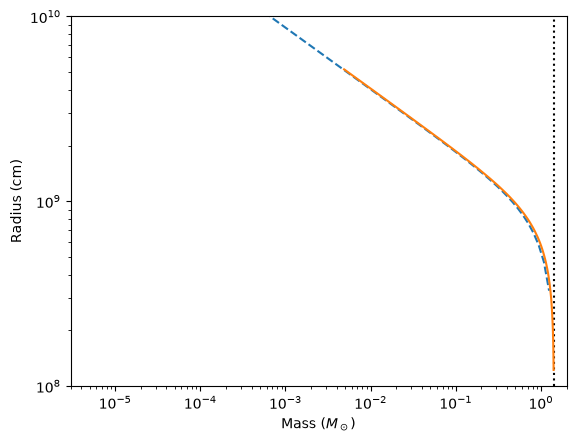

In [5]:
# store the mass-radius relation
mass_computed = np.array([])
radius_computed = np.array([])
density_computed = np.array([])

# we go up to 1e10 g/cm^3
lg_rho_c_q1 = np.linspace(2.0, 10.0, 101)

# compute mass-radius relation via iteration
for rho in lg_rho_c_q1:
    rhov, mv, rv = integrateNoCoulomb(10.0**rho)
    #print(np.log10(rhov[0]),mv[-1]/Msun,np.log10(rv[-1]))
    mass_computed = np.append(mass_computed, mv[-1]/Msun)
    radius_computed = np.append(radius_computed, rv[-1])
    density_computed = np.append(density_computed, rhov[0])

fig1 = plt.figure()

# analytic relations
mass_analytic = -6.0 + (np.log10(1.245)+6.0)*np.arange(101)*0.01
mass_analytic = 10.0**mass_analytic
radius_analytic = 8.7e8 * (mass_analytic**(-1.0/3.0)) * ((1 - ((mass_analytic / MCh)**(4.0/3.0)))**0.5)
plt.plot(mass_analytic, radius_analytic,'--')

# tidy up the plot and save it
plt.ylim((1e8,1e10))
plt.xlim((3e-6,2.0))
plt.xscale('log')
plt.yscale('log')
plt.axvline(mass_computed[-1], ls=':', color = 'k')
plt.ylabel('Radius (cm)')
plt.xlabel(r'Mass ($M_\odot$)')
plt.plot(mass_computed, radius_computed)
plt.show()

In [6]:
print('Chandrasekhar mass limit estimate: ', mass_computed[-1])

Chandrasekhar mass limit estimate:  1.4076742662734814


2.  *Investigate the density profile.* Plot the density profile as a
    function of radius for different mass white dwarfs. How does the
    density profile change as you change the white dwarf mass?

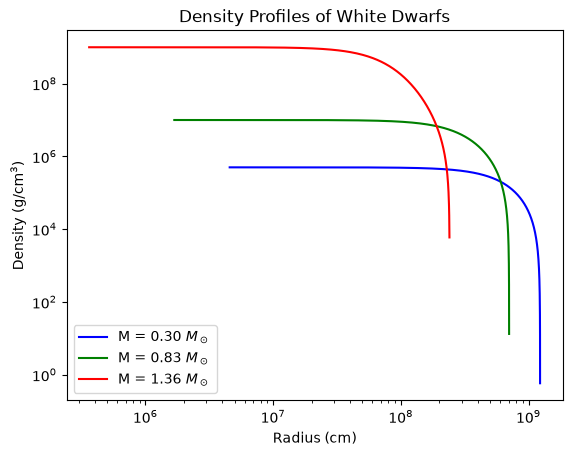

In [7]:
fig_3 = plt.figure()

# Pick 3 or 4 representative central densities (in g/cm^3)
# These correspond to roughly 0.3, 0.8, and 1.3 solar masses
rho_c_list = [5e5, 1e7, 1e9] 
colors = ['blue', 'green', 'red']

for rho_c, color in zip(rho_c_list, colors):
    # Run the integration for this specific star
    rhov, mv, rv = integrateNoCoulomb(rho_c) # Set to False since this is Q2 (no Coulomb yet)
    
    # Calculate the mass of this star for the legend
    mass = mv[-1] / Msun
    
    # Plot density vs radius for THIS star
    plt.plot(rv, rhov, color=color, label=rf'M = {mass:.2f} $M_\odot$')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Radius (cm)')
plt.ylabel('Density (g/cm$^3$)')
plt.legend()
plt.title('Density Profiles of White Dwarfs')
plt.show()

As the white dwarf mass increases, its radius decreases, and its central density increases significantly. Lower mass white dwarfs have a relatively uniform density profile that slowly decays to zero at the surface. Higher mass white dwarfs are much more centrally condensed, with a sharp drop in density near the surface.

3.  *The extent to which the electrons are relativistic.* Plot the value
    of $\gamma = d\ln P/d\ln\rho$ and $E_F/m_ec^2$ at the center of the
    white dwarf as a function of mass. Comment on your results.

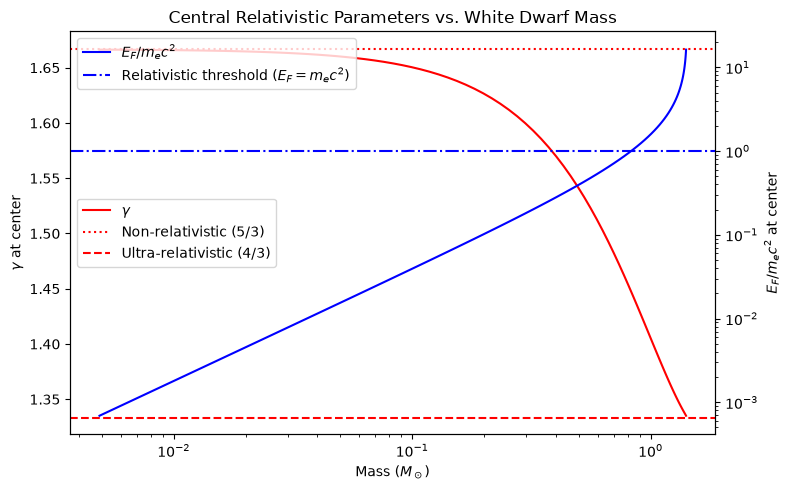

In [8]:
def fermi_energy_ratio(rho):
    Ye = 0.5
    mu_e = 1.0 / Ye # = 2
    m_u = 1.6605e-24 # g
    m_e = 9.1094e-28 # g
    c = 2.9979e10 # cm/s
    hbar = 1.0546e-27 # erg s
    
    # Electron number density
    n_e = rho / (mu_e * m_u)
    
    # Fermi momentum
    p_F = hbar * (3.0 * np.pi**2 * n_e)**(1.0/3.0)
    
    # Ratio x = p_F / (m_e c)
    x = p_F / (m_e * c)
    
    # Return kinetic energy ratio
    return np.sqrt(1.0 + x**2) - 1.0

# Calculate central gamma and Fermi energy ratio for each star
gamma_center = [gammaElectron(rho) for rho in density_computed]
EF_ratio_center = [fermi_energy_ratio(rho) for rho in density_computed]

fig5, ax1 = plt.subplots(figsize=(8, 5))

# Plot Gamma (Left Axis)
ax1.set_xlabel(r'Mass ($M_\odot$)')
ax1.set_ylabel(r'$\gamma$ at center')
ax1.plot(mass_computed, gamma_center, color='r', label=r'$\gamma$')
ax1.set_xscale('log')
ax1.axhline(y=5/3, linestyle=':', color='r', label='Non-relativistic (5/3)')
ax1.axhline(y=4/3, linestyle='--', color='r', label=r'Ultra-relativistic (4/3)')
ax1.legend()

# Plot Fermi Energy Ratio (Right Axis)
ax2 = ax1.twinx()
ax2.set_ylabel(r'$E_F / m_e c^2$ at center')  
ax2.plot(mass_computed, EF_ratio_center, color='b', label=r'$E_F/m_e c^2$')
ax2.set_yscale('log') # Log scale because it spans orders of magnitude
ax2.axhline(y=1.0, linestyle='-.', color='b', label=r'Relativistic threshold ($E_F = m_e c^2$)')
ax2.legend()

plt.title('Central Relativistic Parameters vs. White Dwarf Mass')
fig5.tight_layout()
plt.show()

As the mass of the white dwarf increases, the central density increases.
This causes the Fermi energy of the electrons to increase. For low-mass white dwarfs, $E_F\lt\lt m_e c^2$,
meaning the electrons are non-relativistic, and $\gamma\approx5/3$. As the mass approaches the Chandrasekhar limit,
the Fermi energy exceeds the rest mass energy, meaning the electrons become ultra-relativistic, and $\gamma\approx4/3$.
This softening of the equation of state is what causes the Chandrasekhar mass limit.

4.  *Add the Coulomb pressure of the ions $P_C$ to the electron
    pressure*, i.e. write $P=P_e + P_C$ where $P_e$ is given by equation
    {eq}`eq:Pe` and $P_C$ is given by equation {eq}`eq:PC` of the notes.
    You can then derive the extra term that needs to be added to
    equation {eq}`eq:dlnPdr`. Calculate the new models — what changes?
    At what masses does the Coulomb energy become important?

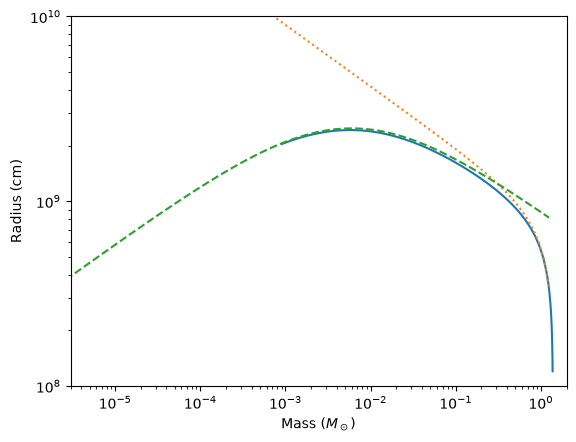

In [9]:
def pressureWithCoulomb(rho):
    # Paczynski's interpolation of the non-relativistic and relatvisitic pressures
    Pe = electronPressure(rho)
    # Coulomb pressure
    Pc = - Kc * rho**(4.0/3.0)
    
    return Pe + Pc

def gammaCoulomb(rho):
    # non-relativistic degenerate electron pressure
    Pnr = Knr * rho**(5.0/3.0) 
    # relativistic degenerate electron pressure
    Pr = Kr * rho**(4.0/3.0)
    # Paczynski's interpolation of the non-relativistic and relatvisitic pressures
    Pe = 1.0 / ((1.0/Pnr)**2 + (1.0/Pr)**2)**0.5
    # Coulomb pressure
    Pc = pressureWithCoulomb(rho) - Pe
    
    ge = (5.0/3.0) * ((Pe / Pnr)**2) + (4.0/3.0) * ((Pe/Pr)**2)
    gc = 4.0/3.0

    # this is how you combine the adiabatic indices when the pressures sum together
    return (Pe*ge + Pc*gc) / (Pe + Pc)

def integrateCoulomb(rho_c):
    # to store the profiles
    rho_vec = np.array([])
    m_vec = np.array([])
    r_vec = np.array([])
    gam_vec = np.array([])

    # step in r
    dr = 1e6 # cm

    # initial conditions
    m = 2e26  # 1e-7 of a solar mass
    r = (3.0 * m / (4.0 * np.pi * rho_c)) ** (1.0/3.0)
    rho = rho_c
    dlnPdlnrho = gammaCoulomb(rho_c)

    rho_stop = rho_0

    # take steps until we reach the surface
    while rho > rho_stop:
    
        # store the latest step
        rho_vec = np.append(rho_vec,rho)    
        r_vec = np.append(r_vec,r)    
        m_vec = np.append(m_vec,m)    
        gam_vec = np.append(gam_vec,dlnPdlnrho)
      
        # calculate dP/drho
        P = pressureWithCoulomb(rho)

        # derivatives    
        dmdr = 4.0 * np.pi * r**2 * rho
        dPdr = - 6.67e-8 * m * rho / r**2
        dlnPdlnrho = gammaCoulomb(rho)
        drhodr = (rho/P) * dPdr / dlnPdlnrho 
   
        # take a step
        r = r + dr
        m = m + dmdr * dr
        rho = rho + drhodr * dr
    
    return rho_vec, m_vec, r_vec

# store the mass-radius relation
mass_computed = np.array([])
radius_computed = np.array([])
density_computed = np.array([])

# central densities to consider
# this is fractionally how much above the zero-pressure density the starting density should be (sets the lowest mass)
eps1 = 0.03
# we go from there (3% above zero-pressure density) to 1e10 g/cm^3
lg_rho_c_q4 = np.linspace(2.0, 10.0, 101)

# compute mass-radius relation via iteration
for rho in lg_rho_c_q4:
    rhov, mv, rv = integrateCoulomb(10.0**rho)
    #print(np.log10(rhov[0]),mv[-1]/Msun,np.log10(rv[-1]))
    mass_computed = np.append(mass_computed, mv[-1]/Msun)
    radius_computed = np.append(radius_computed, rv[-1])
    density_computed = np.append(density_computed, rhov[0])

fig2 = plt.figure()

plt.plot(mass_computed, radius_computed)

# analytic relations
mass_analytic = -6.0 + (np.log10(1.245)+6.0)*np.arange(101)*0.01
mass_analytic = 10.0**mass_analytic
# this is the WD mass radius relation approximation using Paczynski to 
# interpolate between the non-relativistic and relativistic pressures
radius_analytic_nocoulomb = 2.36 * Knr / (6.67e-8*(mass_analytic*Msun)**0.333) * (1.0 - (mass_analytic/MCh)**(4.0/3.0))**0.5
plt.plot(mass_analytic,radius_analytic_nocoulomb,':')

# this is a modified version of the formula given in the notes for the 
# radius when Coulomb pressure is included. I added constants to each term
# so that it gives the correct answer in the low and high mass limits
radius_analytic_coulomb = Knr / (6.67e-8*(mass_analytic*Msun)**0.333/2.36 + Kc/(mass_analytic*Msun)**0.333 * (4.0*np.pi/3.0)**(1.0/3.0))
plt.plot(mass_analytic, radius_analytic_coulomb,'--')

plt.ylim((1e8,1e10))
plt.xlim((3e-6,2.0))
plt.xscale('log')
plt.yscale('log')
plt.ylabel('Radius (cm)')
plt.xlabel(r'Mass ($M_\odot$)')

plt.show()

In [10]:
print('Chandrasekhar mass limit estimate: ', mass_computed[-1])

Chandrasekhar mass limit estimate:  1.3698193749490635


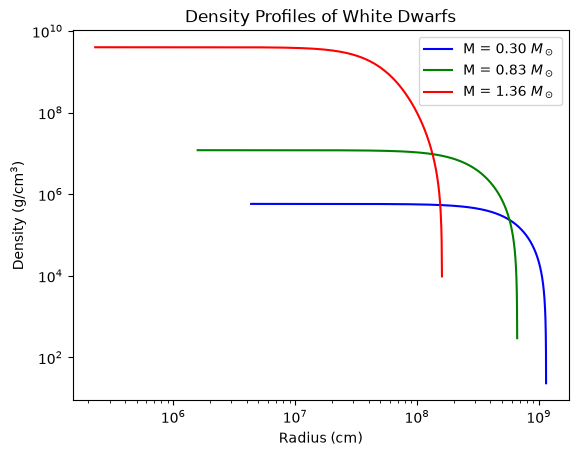

In [11]:
fig_33 = plt.figure()

# Pick 3 or 4 representative central densities (in g/cm^3)
# These correspond to roughly 0.3, 0.8, and 1.3 solar masses
rho_c_list = [5.8e5, 1.2e7, 4e9] 
colors = ['blue', 'green', 'red']

for rho_c, color in zip(rho_c_list, colors):
    # Run the integration for this specific star
    rhov, mv, rv = integrateCoulomb(rho_c) # Set to False since this is Q2 (no Coulomb yet)
    
    # Calculate the mass of this star for the legend
    mass = mv[-1] / Msun
    
    # Plot density vs radius for THIS star
    plt.plot(rv, rhov, color=color, label=rf'M = {mass:.2f} $M_\odot$')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Radius (cm)')
plt.ylabel('Density (g/cm$^3$)')
plt.legend()
plt.title('Density Profiles of White Dwarfs')
plt.show()

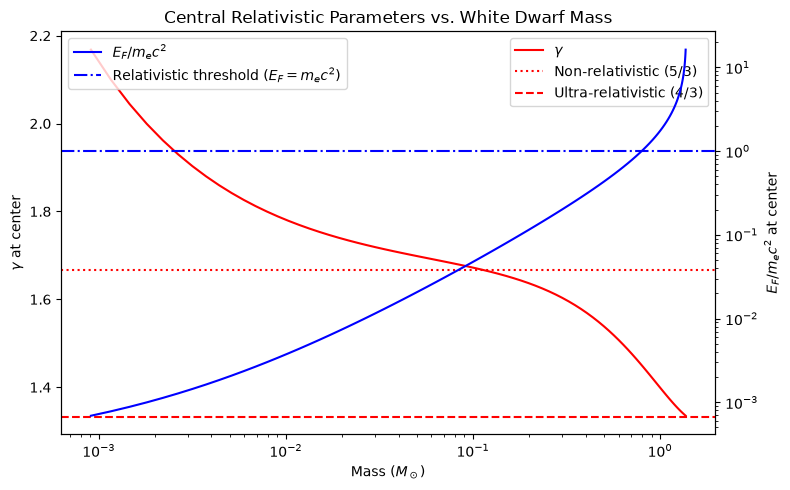

In [12]:
# Calculate central gamma and Fermi energy ratio for each star
gamma_center = [gammaCoulomb(rho) for rho in density_computed]
EF_ratio_center = [fermi_energy_ratio(rho) for rho in density_computed]

fig6, ax1 = plt.subplots(figsize=(8, 5))

# Plot Gamma (Left Axis)
ax1.set_xlabel(r'Mass ($M_\odot$)')
ax1.set_ylabel(r'$\gamma$ at center')
ax1.plot(mass_computed, gamma_center, color='r', label=r'$\gamma$')
ax1.set_xscale('log')
ax1.axhline(y=5/3, linestyle=':', color='r', label='Non-relativistic (5/3)')
ax1.axhline(y=4/3, linestyle='--', color='r', label=r'Ultra-relativistic (4/3)')
ax1.legend()

# Plot Fermi Energy Ratio (Right Axis)
ax2 = ax1.twinx()
ax2.set_ylabel(r'$E_F / m_e c^2$ at center')  
ax2.plot(mass_computed, EF_ratio_center, color='b', label=r'$E_F/m_e c^2$')
ax2.set_yscale('log') # Log scale because it spans orders of magnitude
ax2.axhline(y=1.0, linestyle='-.', color='b', label=r'Relativistic threshold ($E_F = m_e c^2$)')
ax2.legend()

plt.title('Central Relativistic Parameters vs. White Dwarf Mass')
fig6.tight_layout()
plt.show()

Including the Coulomb pressure reduces the total pressure because the Coulomb interaction is attractive. Consequently, the equation of state is softened. To support the same mass, the white dwarf must contract slightly, meaning its radius is smaller for a given mass. More importantly, the maximum mass (Chandrasekhar limit) decreases from approximately 1.40 to 1.37 solar masses.

By comparing the numerical mass-radius relations with and without Coulomb pressure, we see that the two curves overlap almost perfectly for low masses. At these low masses, the central density is low, and the Coulomb pressure is negligible compared to the electron degeneracy pressure. The curves begin to visibly diverge at intermediate masses. The effect is most significant near the Chandrasekhar limit, where the density is highest, making the Coulomb correction substantial and causing a measurable drop in the maximum mass.